# 🎮 Sesión 2: Extracción de Grafos (Caso Twitch)
De datos tabulares a topología de red.

## 🧠 Teoría Fundamental: De la Tabla a la Red
En el mundo real, los grafos rara vez vienen estructurados. Se **extraen** de bases de datos relacionales o logs transaccionales mediante ingeniería de datos.

### 1. El Grafo Bipartito
Es una red donde los nodos se dividen en dos conjuntos disjuntos (Ej. `Usuarios` y `Películas`, o `Clientes` y `Productos`). Las conexiones solo pueden existir **cruzando** de un conjunto a otro. Dos usuarios no pueden conectarse entre sí directamente.

### 2. Grafos de Co-ocurrencia (Colapsando la Red)
Para encontrar relaciones entre elementos del mismo conjunto (Ej. qué tan similares son dos usuarios, o qué productos se compran juntos), "colapsamos" el grafo bipartito. Si el *Usuario A* y el *Usuario B* vieron la misma película, creamos una arista directa entre ellos. El **peso** de la arista aumenta por cada iteración que compartan.

### 3. Centralidad de Grado (Degree Centrality)
Mide el poder topológico de un nodo basándose en la cantidad de conexiones proporcionales que tiene respecto al total de la red. Sirve para encontrar los "Hubs" o cuellos de botella.
$$ C_d(v) = \frac{deg(v)}{N - 1} $$

In [9]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# 1. Cargar el Log
df = pd.read_csv('dataset/twitch_raids_y_collabs.csv')
display(df.head())

,Streamer_Origen,Streamer_Destino,Tipo_Interaccion
0,Rubius,Spreen,Raid
1,Rivers,AriGameplays,Co-op
2,Ibai,Spreen,Raid
3,Rivers,Spreen,Co-op
4,Ibai,Auronplay,Host


In [10]:
# 2. Extraer Pesos (Frecuencia de interacción)
interacciones = df.groupby(['Streamer_Origen', 'Streamer_Destino']).size().reset_index(name='Peso')
display(interacciones.head())

,Streamer_Origen,Streamer_Destino,Peso
0,AriGameplays,Auronplay,1
1,AriGameplays,ElMariana,2
2,AriGameplays,Ibai,2
3,AriGameplays,JuanSGuarnizo,4
4,AriGameplays,Quackity,1


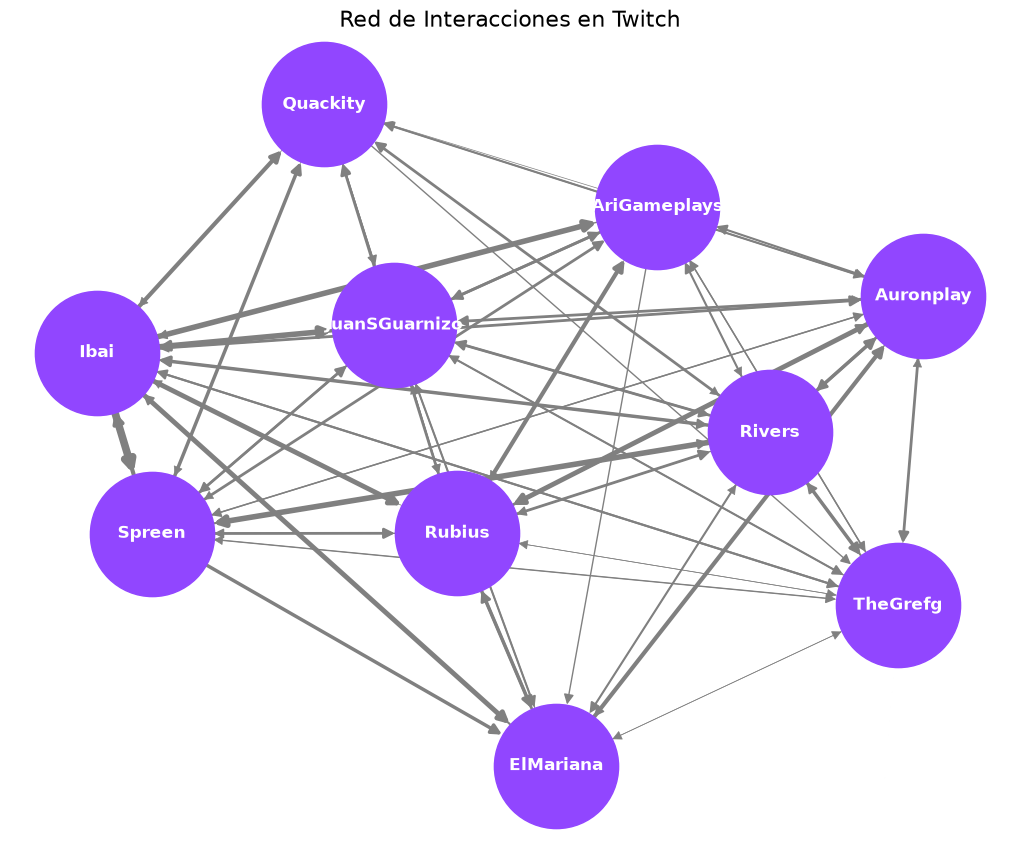

In [11]:
# 3. Construir Grafo desde Pandas
G_twitch = nx.from_pandas_edgelist(interacciones, source='Streamer_Origen', target='Streamer_Destino', edge_attr='Peso', create_using=nx.DiGraph())

# 4. Visualización con pesos
plt.figure(figsize=(10,8))
pos = nx.spring_layout(G_twitch, seed=42)
pesos = [d['Peso']*0.5 for (u, v, d) in G_twitch.edges(data=True)]
nx.draw(G_twitch, pos, with_labels=True, node_color='#9146FF', node_size=8000, font_color='white', font_weight='bold', width=pesos, edge_color='gray', arrowsize=15)
plt.title('Red de Interacciones en Twitch', fontsize=16)
plt.show()

In [12]:
# Calcula qué porcentaje de la red está conectado a cada streamer
nx.degree_centrality(G_twitch)

{'AriGameplays': 1.7777777777777777,
 'Auronplay': 2.0,
 'ElMariana': 1.5555555555555554,
 'Ibai': 2.0,
 'JuanSGuarnizo': 2.0,
 'Quackity': 1.5555555555555554,
 'Rivers': 2.0,
 'Rubius': 2.0,
 'Spreen': 1.8888888888888888,
 'TheGrefg': 1.8888888888888888}

--
## FASE 1: Limpieza

In [2]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# 1. Cargar el Log
df = pd.read_csv('compras_ecommerce.csv')
print('Filas originales:', len(df))
print('Productos distintos (sin limpiar):', df['Producto'].nunique())
display(df.head())
display(df.isna().sum())

Filas originales: 6858
Productos distintos (sin limpiar): 20


,ID_Transaccion,Producto
0,TKT-00181,Teclado Mecánico RGB
1,TKT-01162,"Monitor 27"" 144Hz"
2,TKT-00840,Silla Gamer Ergonómica
3,TKT-01734,silla gamer ergonómica
4,TKT-01899,Mousepad XL


ID_Transaccion      0
Producto          150
dtype: int64

In [14]:
# 1. Eliminar filas
df = df.dropna(subset=['Producto'])
print('Nulos:', len(df))

# 2. Estandarizar
df['Producto'] = df['Producto'].str.strip().str.upper()
print('Estandar:', df['Producto'].nunique())

# 3. Fallos
df = df[df['ID_Transaccion'] != 'ERR_TIMEOUT']
print('ERR_TIMEOUT:', len(df))

# 4. Self-loops
df = df.drop_duplicates(subset=['ID_Transaccion', 'Producto'])
print('Duplicados por ticket:', len(df))
print('Tickets únicos:', df['ID_Transaccion'].nunique())

Nulos: 6258
Estandar: 10
ERR_TIMEOUT: 6258
Duplicados por ticket: 6258
Tickets únicos: 2494


## FASE 2: Extracción

In [4]:
cruce = pd.merge(df, df, on='ID_Transaccion', suffixes=('_A', '_B'))
print('Filas tras el merge:', len(cruce))

cruce = cruce[cruce['Producto_A'] < cruce['Producto_B']]
print('Filas tras filtrar self-loops y espejos:', len(cruce))

aristas = (cruce.groupby(['Producto_A', 'Producto_B'])
                .size()
                .reset_index(name='Peso')
                .sort_values('Peso', ascending=False)
                .reset_index(drop=True))
print('Pares únicos (aristas):', len(aristas))
display(aristas)

Filas tras el merge: 17766
Filas tras filtrar self-loops y espejos: 5754
Pares únicos (aristas): 45


,Producto_A,Producto_B,Peso
0,AUDÍFONOS BLUETOOTH,WEBCAM 1080P,364
1,MOUSE INALÁMBRICO,WEBCAM 1080P,361
2,MOUSEPAD XL,TECLADO MECÁNICO RGB,359
3,"MONITOR 27"" 144HZ",MOUSEPAD XL,358
4,LAPTOP PRO 15,WEBCAM 1080P,351
5,SILLA GAMER ERGONÓMICA,TECLADO MECÁNICO RGB,351
6,"MONITOR 27"" 144HZ",TECLADO MECÁNICO RGB,350
7,LAPTOP PRO 15,MOUSE INALÁMBRICO,347
8,MOUSEPAD XL,SILLA GAMER ERGONÓMICA,346
9,AUDÍFONOS BLUETOOTH,LAPTOP PRO 15,341


## FASE 3: Respuesta de Negocio

In [15]:
G = nx.from_pandas_edgelist(aristas, source='Producto_A', target='Producto_B', edge_attr='Peso')
print('Nodos:', G.number_of_nodes(), '| Aristas:', G.number_of_edges())
print('Densidad:', round(nx.density(G), 3))

Nodos: 10 | Aristas: 45
Densidad: 1.0


In [16]:
dc = pd.Series(nx.degree_centrality(G)).sort_values(ascending=False)
display(dc.round(3).to_frame('Degree Centrality'))
print('Producto con mayor Degree Centrality:', dc.index[0], '->', dc.iloc[0])
print('¿Todos empatados?', dc.nunique() == 1)

,Degree Centrality
AUDÍFONOS BLUETOOTH,1.0
WEBCAM 1080P,1.0
MOUSE INALÁMBRICO,1.0
MOUSEPAD XL,1.0
TECLADO MECÁNICO RGB,1.0
"MONITOR 27"" 144HZ",1.0
LAPTOP PRO 15,1.0
SILLA GAMER ERGONÓMICA,1.0
MICRÓFONO DE CONDENSADOR,1.0
CABLE HDMI 2.1,1.0


Producto con mayor Degree Centrality: AUDÍFONOS BLUETOOTH -> 1.0
¿Todos empatados? True


In [7]:
fuerza = pd.Series(dict(G.degree(weight='Peso'))).sort_values(ascending=False)
display(fuerza.to_frame('Fuerza (suma de pesos)'))
print('PRODUCTO ANCLA (por fuerza ponderada):', fuerza.index[0])

,Fuerza (suma de pesos)
WEBCAM 1080P,1721
"MONITOR 27"" 144HZ",1648
TECLADO MECÁNICO RGB,1252
MOUSE INALÁMBRICO,1226
MOUSEPAD XL,1214
LAPTOP PRO 15,1170
AUDÍFONOS BLUETOOTH,1167
SILLA GAMER ERGONÓMICA,1167
MICRÓFONO DE CONDENSADOR,697
CABLE HDMI 2.1,246


PRODUCTO ANCLA (por fuerza ponderada): WEBCAM 1080P


In [8]:
objetivo = 'TECLADO MECÁNICO RGB'
vecinos = sorted(((v, d['Peso']) for v, d in G[objetivo].items()), key=lambda x: x[1], reverse=True)
display(pd.DataFrame(vecinos, columns=['Producto vecino', 'Peso']))
print(f'RECOMENDAR a quien compra {objetivo}: {vecinos[0][0]} (peso {vecinos[0][1]})')

,Producto vecino,Peso
0,MOUSEPAD XL,359
1,SILLA GAMER ERGONÓMICA,351
2,"MONITOR 27"" 144HZ",350
3,MOUSE INALÁMBRICO,37
4,WEBCAM 1080P,34
5,LAPTOP PRO 15,33
6,CABLE HDMI 2.1,33
7,MICRÓFONO DE CONDENSADOR,29
8,AUDÍFONOS BLUETOOTH,26


RECOMENDAR a quien compra TECLADO MECÁNICO RGB: MOUSEPAD XL (peso 359)


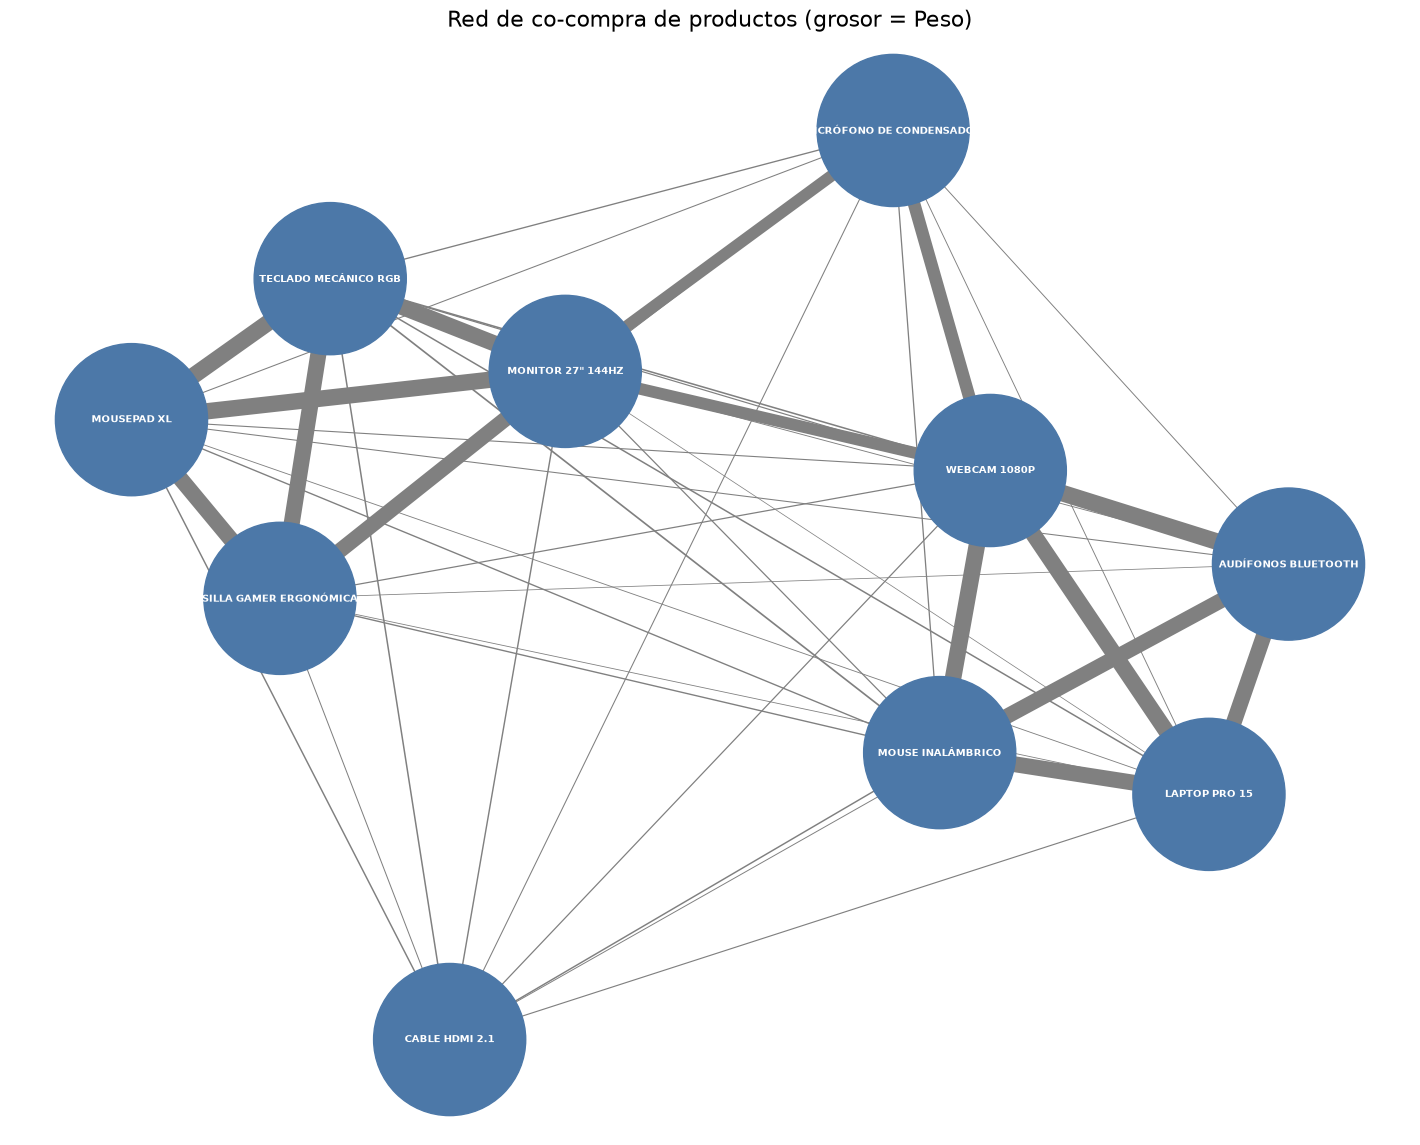

In [30]:
plt.figure(figsize=(14, 11))
pos = nx.spring_layout(G, seed=42, k=1.2, weight='Peso')
pesos = [d['Peso'] for _, _, d in G.edges(data=True)]
anchos = [w / max(pesos) * 12 for w in pesos]
tamanos = [3000 + 9000 * dc[n] for n in G.nodes()]
nx.draw(G, pos, with_labels=True, node_color='#4C78A8', node_size=tamanos,
        font_size=7, font_color='white', font_weight='bold',
        width=anchos, edge_color='gray', alpha=1)
plt.title('Red de co-compra de productos (grosor = Peso)', fontsize=16)
plt.show()